# Katrina three-panel figure: relative risk, population density, attributable person-years

Runs `idd_tc_mortality.viz.storm_three_panel` in two steps so you can restyle without recomputing:

1. `prepare_arrays(...)` loads the stage-1 intensity grid, the RR-by-windspeed curve, the 0.01° population
   window and the admin-1 polygons, and derives the three arrays plus totals and titles (`PanelData`).
2. `build_figure(data, **style)` lays them out with idd-figures (`panel_grid`): a maps row over a colorbar row.

Inputs and their sources are documented in the module docstring. The CLI equivalent is `run-storm-three-panel`.


In [1]:
%matplotlib inline
from idd_figures.lib.io import save_figure
from idd_tc_mortality.viz import storm_three_panel as stp

## 1. Data choices

In [2]:
data = stp.prepare_arrays(
    storm_id="2005236N23285",   # IBTrACS id = stage-1 file stem
    basin="NA",
    outcome="resp",             # "resp" (rd_rr_samples.csv) or "cvd" (cvd_rr_samples.csv)
    rr_sample="mean",           # RR table column: mean, min, max, sample_001, ...
    impact_days=20.0,           # fixed impact duration per affected pixel (notebook assumption)
    pop_year=None,              # None -> storm year
    adm1_name=None,             # e.g. "Louisiana" to mask + total within one state (Hubei-style)
    pad_deg=0.5,                # padding around the RR>0 bbox when no admin unit is given
)
data.totals

{'population': 104752026.23702466,
 'person_years': 110124.65535030988,
 'affected_population': 16989273.830420565}

## 2. Style knobs

All arguments below are `build_figure` keywords with their defaults; change any and re-run this cell only.
Heights are inches. Colormaps are matplotlib names.

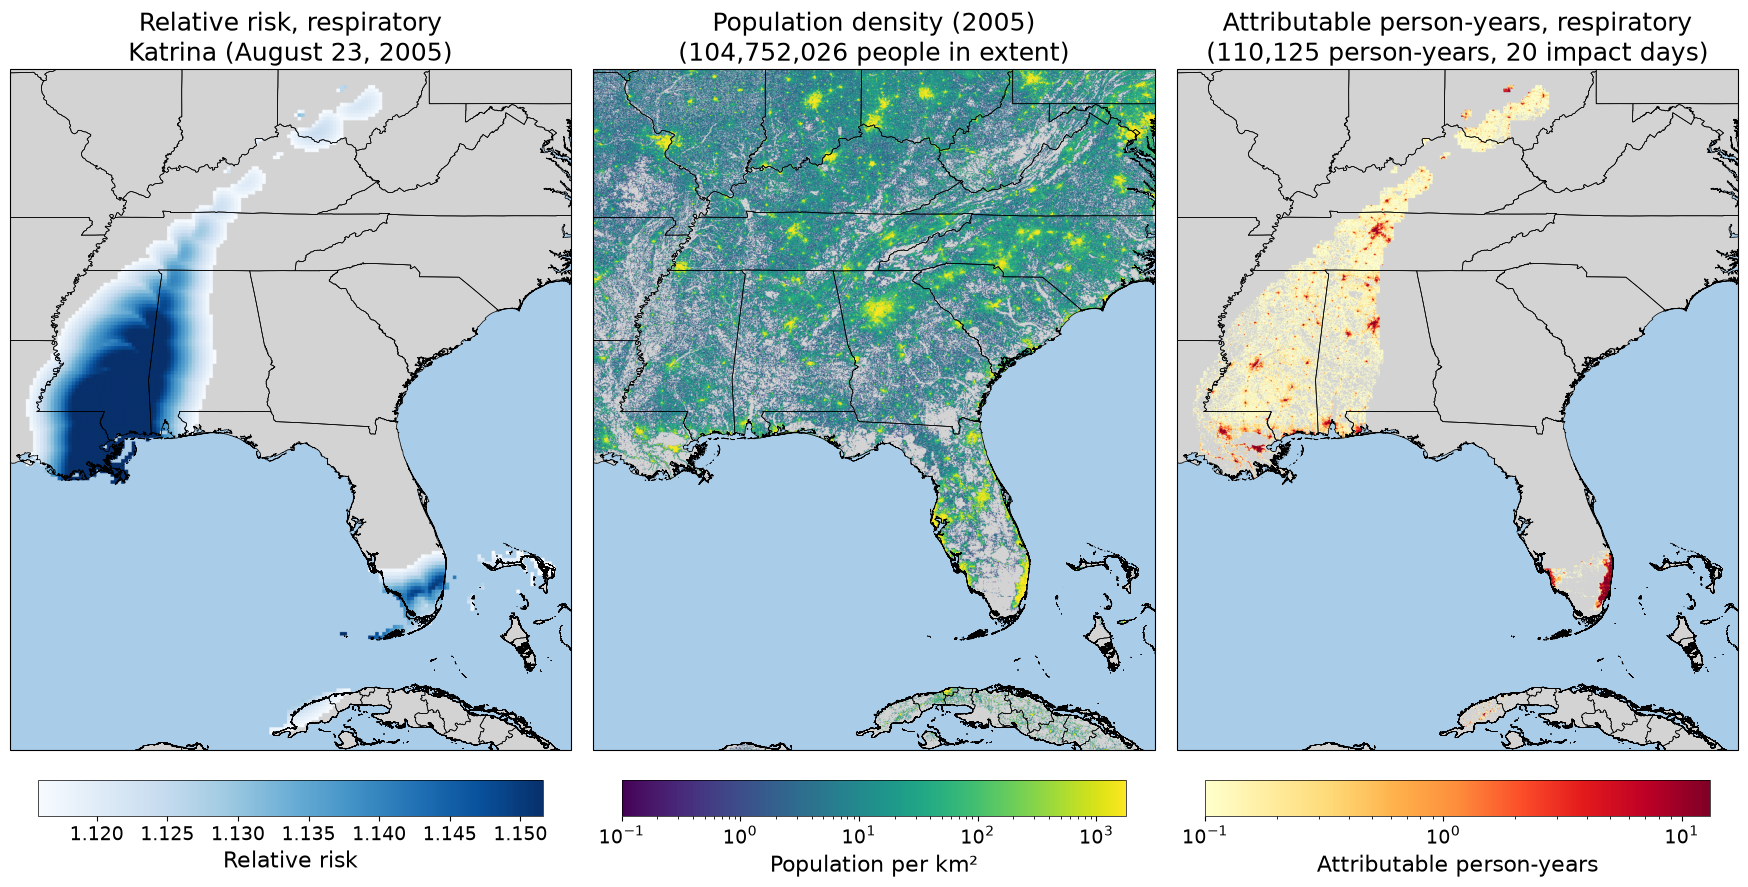

In [3]:
style = dict(
    fig_width=18.0,
    wspace=0.04,                 # gap between panels, fraction of a panel width
    title_h=1.0,                 # top allowance for the two-line panel titles
    gap_h=0.25,                  # map-to-colorbar gap
    cbar_h=0.9,                  # colorbar row height (ramp + ticks + label)
    bottom_pad_h=0.1,
    title_fontsize=18,
    cbar_fontsize=14,
    cbar_label_fontsize=16,
    cbar_labels=("Relative risk", "Population per km²", "Attributable person-years"),
    rr_cmap="Blues",
    density_cmap="viridis",
    person_years_cmap="YlOrRd",
    water_color="#A9CCE8",       # axes background = water
    water_alpha=1.0,
    land_color="lightgray",      # admin polygons under the rasters = land without data
    boundary_style={"color": "black", "linewidth": 0.5},   # admin-1 outlines
    unit_style={"color": "red", "linewidth": 1.5},         # the restricted unit's outline
)
fig = stp.build_figure(data, **style)

## 3. Save (working slot of the figures node; overwritten every run)

In [ ]:
out = stp.OUT_DIR / "2005236N23285_resp_three_panel.png"
save_figure(fig, out, dpi=200)

## 4. Two-panel exposure figure: max intensity and exposure hours

Same storm, native stage-1 grid (0.1°): per-pixel maximum wind speed and hours with wind above the
threshold stored in the file (17 m/s). `prepare_exposure_arrays` loads both grids;
`build_exposure_figure` takes the same layout/style keywords as `build_figure` plus its own colormaps.

In [4]:
exp = stp.prepare_exposure_arrays(
    storm_id="2005236N23285",
    basin="NA",
    pad_deg=0.5,            # padding around the intensity > 0 bbox
)

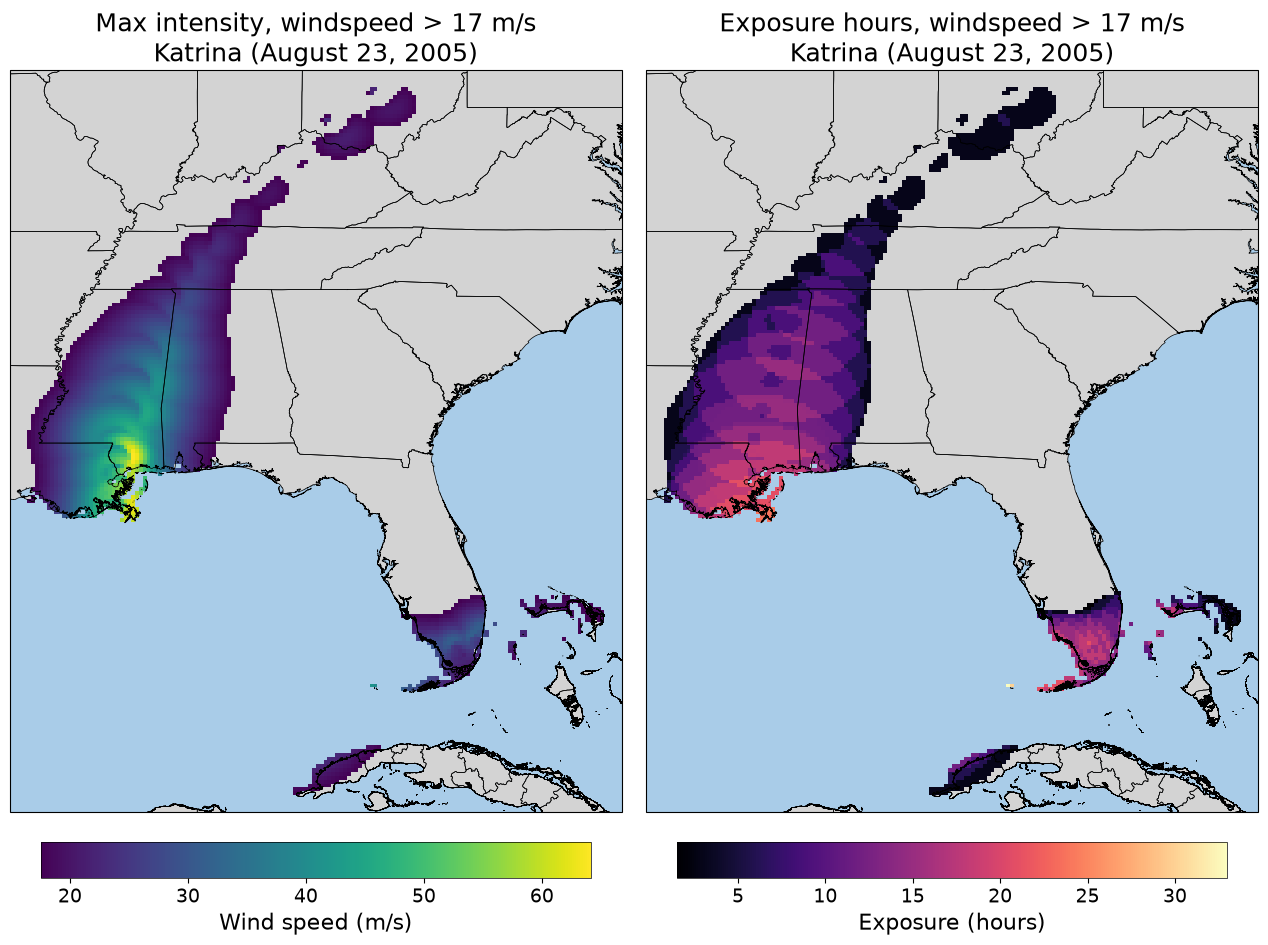

In [5]:
exp_style = dict(
    fig_width=13.0,
    wspace=0.04,
    title_h=1.0,
    gap_h=0.25,
    cbar_h=0.9,
    bottom_pad_h=0.1,
    title_fontsize=18,
    cbar_fontsize=14,
    cbar_label_fontsize=16,
    intensity_cmap="viridis",
    hours_cmap="magma",
    cbar_labels=("Wind speed (m/s)", "Exposure (hours)"),
    water_color="#A9CCE8",
    water_alpha=1.0,
    land_color="lightgray",
    boundary_style={"color": "black", "linewidth": 0.5},
)
fig2 = stp.build_exposure_figure(exp, **exp_style)

In [6]:
out2 = stp.OUT_DIR / "2005236N23285_exposure_two_panel.png"
save_figure(fig2, out2, dpi=200)

[PosixPath('/mnt/team/idd/pub/idd_tc_mortality/05-figures/working/2005236N23285_exposure_two_panel.png')]

[PosixPath('/mnt/team/idd/pub/idd_tc_mortality/05-figures/working/2005236N23285_exposure_rr_three_panel.png')]

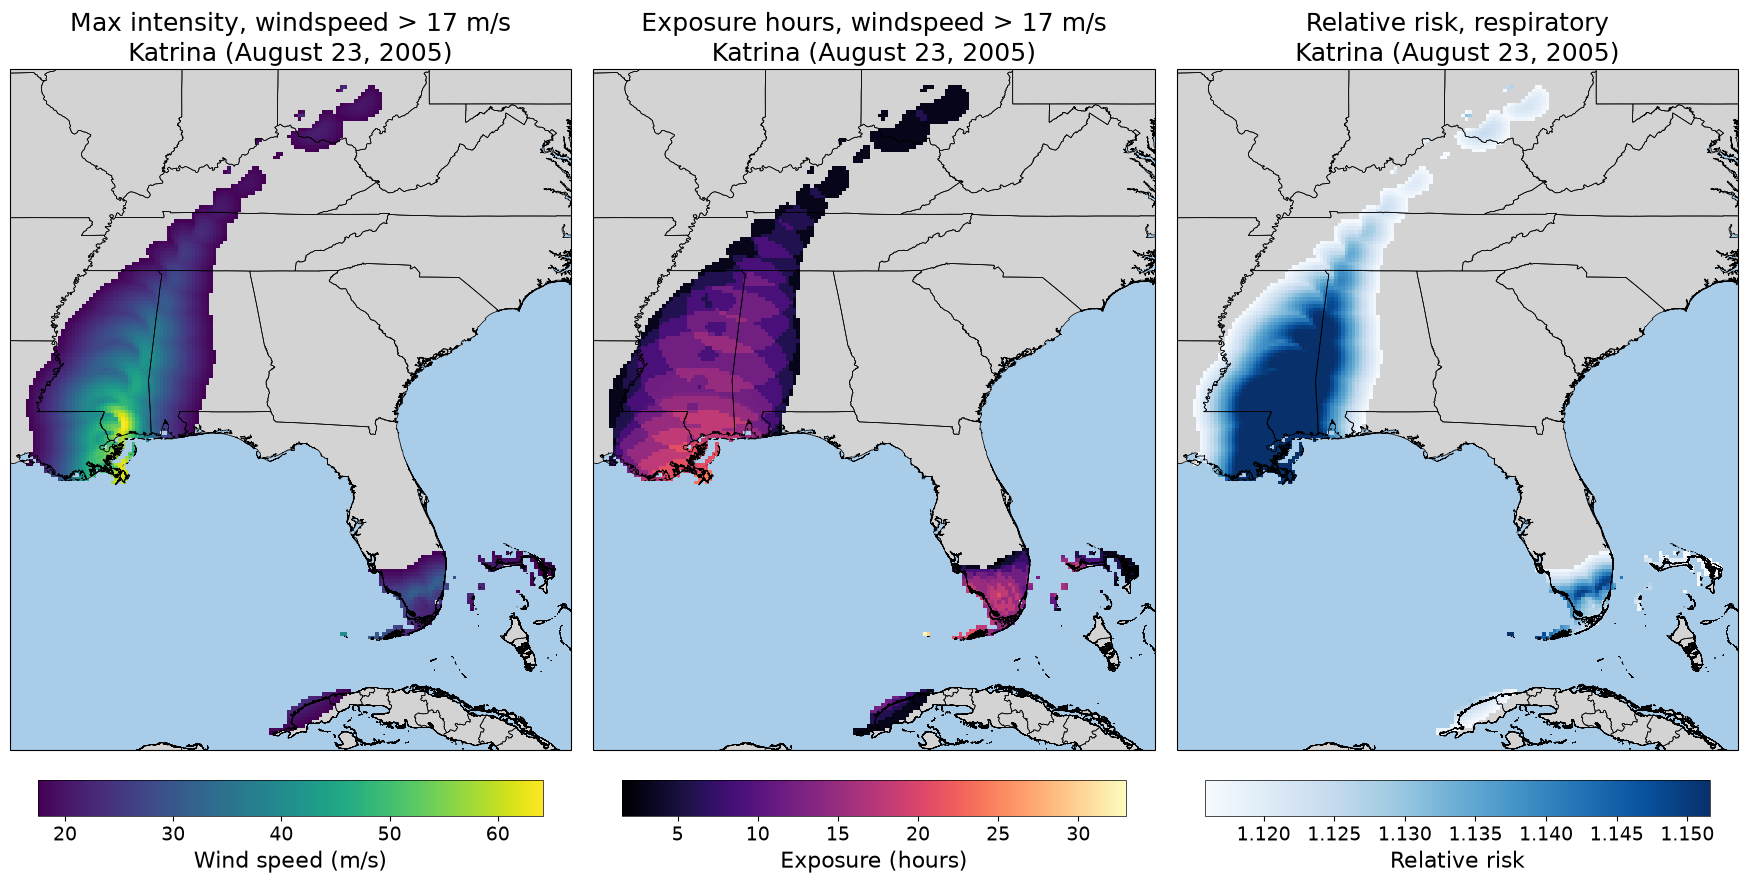

In [7]:
curve = stp.load_rr_curve("resp")
rr_coarse = stp.positive_or_nan(
    stp.rr_from_intensity(exp.intensity, curve["windspeed"].values, curve["mean"].values)
)

specs = [
    stp.PanelSpec(exp.intensity, "viridis", exp.titles[0], "Wind speed (m/s)", "intensity"),
    stp.PanelSpec(exp.exposure_hours, "magma", exp.titles[1], "Exposure (hours)", "exposure_hours"),
    stp.PanelSpec(rr_coarse, "Blues", data.titles[0], "Relative risk", "rr"),
]

fig3 = stp.build_panel_row(
    specs,
    raster_extent=exp.raster_extent,
    extent=exp.extent,
    land_gdf=exp.land_gdf,
    boundary_gdf=exp.land_gdf,
    fig_width=18.0,
    title_fontsize=18,
    cbar_fontsize=14,
    cbar_label_fontsize=16,
    water_color="#A9CCE8",
    land_color="lightgray",
)
save_figure(fig3, stp.OUT_DIR / "2005236N23285_exposure_rr_three_panel.png", dpi=200)


[PosixPath('/mnt/team/idd/pub/idd_tc_mortality/05-figures/working/2005236N23285_person_hours_three_panel.png')]

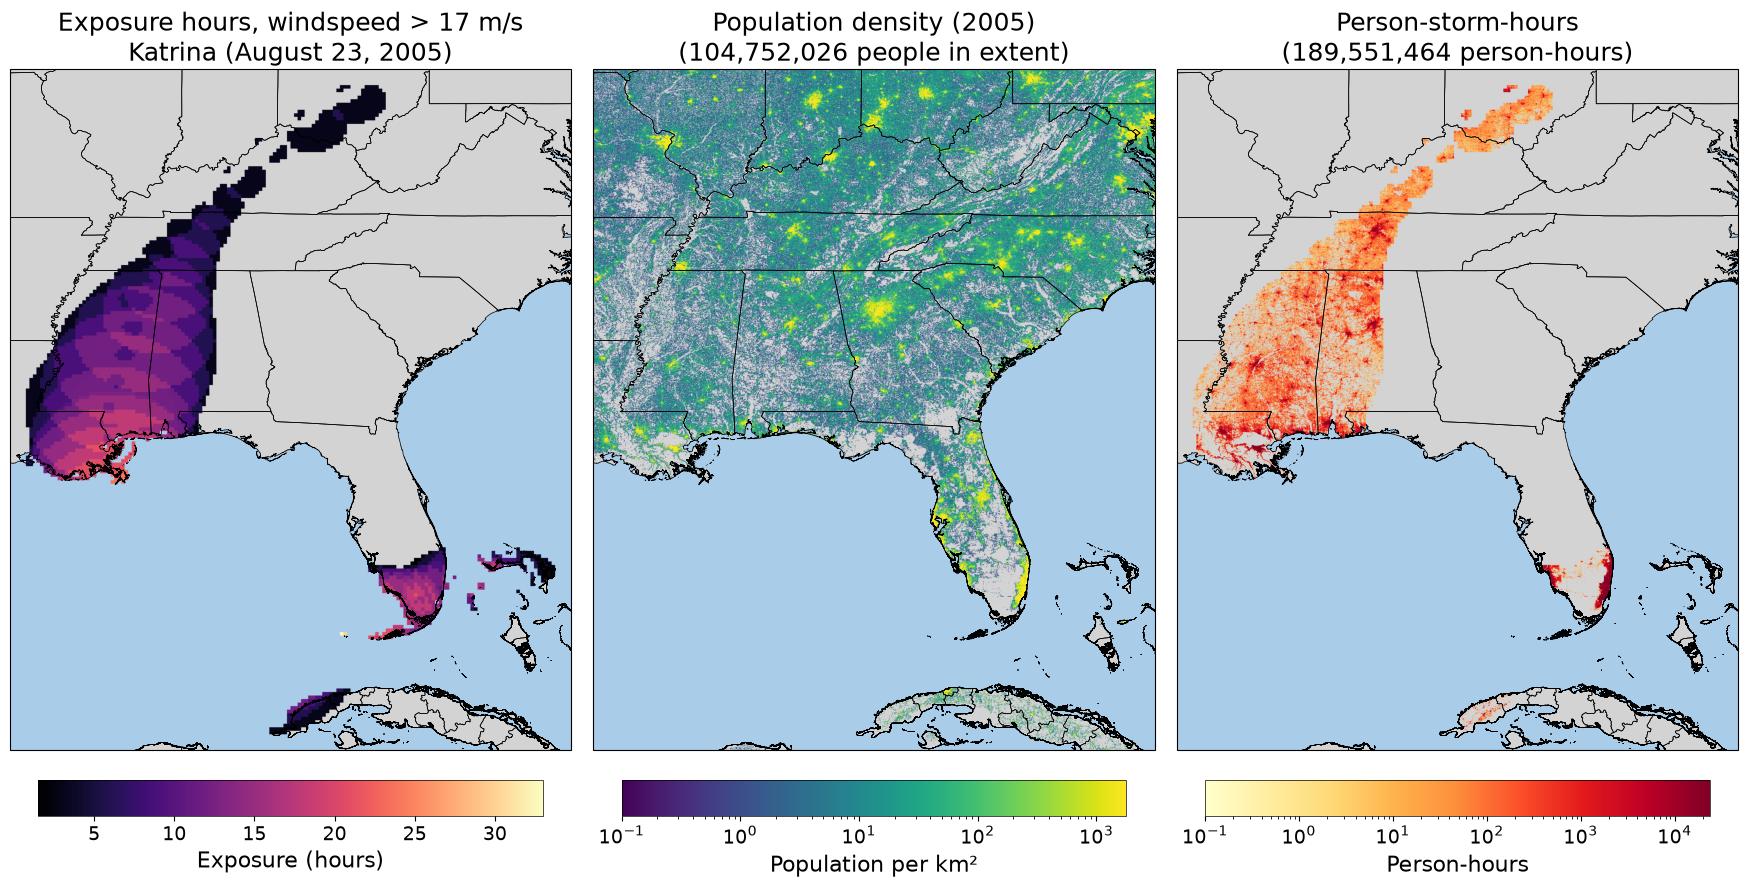

In [8]:
import numpy as np

hours_da = stp.load_exposure_hours("2005236N23285", "NA")
counts, lat_p, lon_p, edges = stp.read_population_window(stp.POP_DIR / "2005q1.tif", exp.extent)
counts = stp.positive_or_nan(counts)

hours = stp.positive_or_nan(
    stp.nearest_resample(hours_da.values, hours_da["lat"].values, hours_da["lon"].values, lat_p, lon_p)
)
density = counts / stp.pixel_area_km2(lat_p, abs(lon_p[1] - lon_p[0]))[:, None]
person_hours = stp.positive_or_nan(hours * counts)

dens_norm, ph_norm = stp.log_norm(density), stp.log_norm(person_hours)
specs = [
    stp.PanelSpec(hours, "magma", exp.titles[1], "Exposure (hours)", "hours"),
    stp.PanelSpec(
        density, "viridis",
        f"Population density (2005)\n({np.nansum(counts):,.0f} people in extent)",
        "Population per km²", "density", norm=dens_norm, ticks=stp.decade_ticks(dens_norm),
    ),
    stp.PanelSpec(
        person_hours, "YlOrRd",
        f"Person-storm-hours\n({np.nansum(person_hours):,.0f} person-hours)",
        "Person-hours", "person_hours", norm=ph_norm, ticks=stp.decade_ticks(ph_norm),
    ),
]

fig4 = stp.build_panel_row(
    specs,
    raster_extent=edges,
    extent=exp.extent,
    land_gdf=exp.land_gdf,
    boundary_gdf=exp.land_gdf,
    fig_width=18.0,
    title_fontsize=18,
    cbar_fontsize=14,
    cbar_label_fontsize=16,
    water_color="#A9CCE8",
    land_color="lightgray",
)
save_figure(fig4, stp.OUT_DIR / "2005236N23285_person_hours_three_panel.png", dpi=200)
